<a href="https://colab.research.google.com/github/alaahaise/Time-Series-Forecasting-with-ARIMA/blob/main/ARIMA_passengers_forcast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
import plotly.express as px
import pandas as pd
from scipy.stats import boxcox
import numpy as np
from statsmodels.graphics.tsaplots import plot_pacf, plot_acf
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from scipy.special import inv_boxcox



uploaded = files.upload()

Saving AirPassengers.csv to AirPassengers.csv


In [ ]:
# Import packages

# Read in the data
data = pd.read_csv('AirPassengers.csv')  # File is now in Colab's working directory
data['Month'] = pd.to_datetime(data['Month'])

# Function to plot passenger volumes
def plot_passenger_volumes(df: pd.DataFrame, y: str) -> None:
    """General function to plot the passenger data."""
    fig = px.line(df, x='Month', y=y, labels={'Month': 'Date'})
    fig.update_layout(template="simple_white", font=dict(size=18),
                      title_text='Airline Passengers', width=650,
                      title_x=0.5, height=400)
    fig.show()

# Plot the airline passenger data
plot_passenger_volumes(df=data, y='#Passengers')


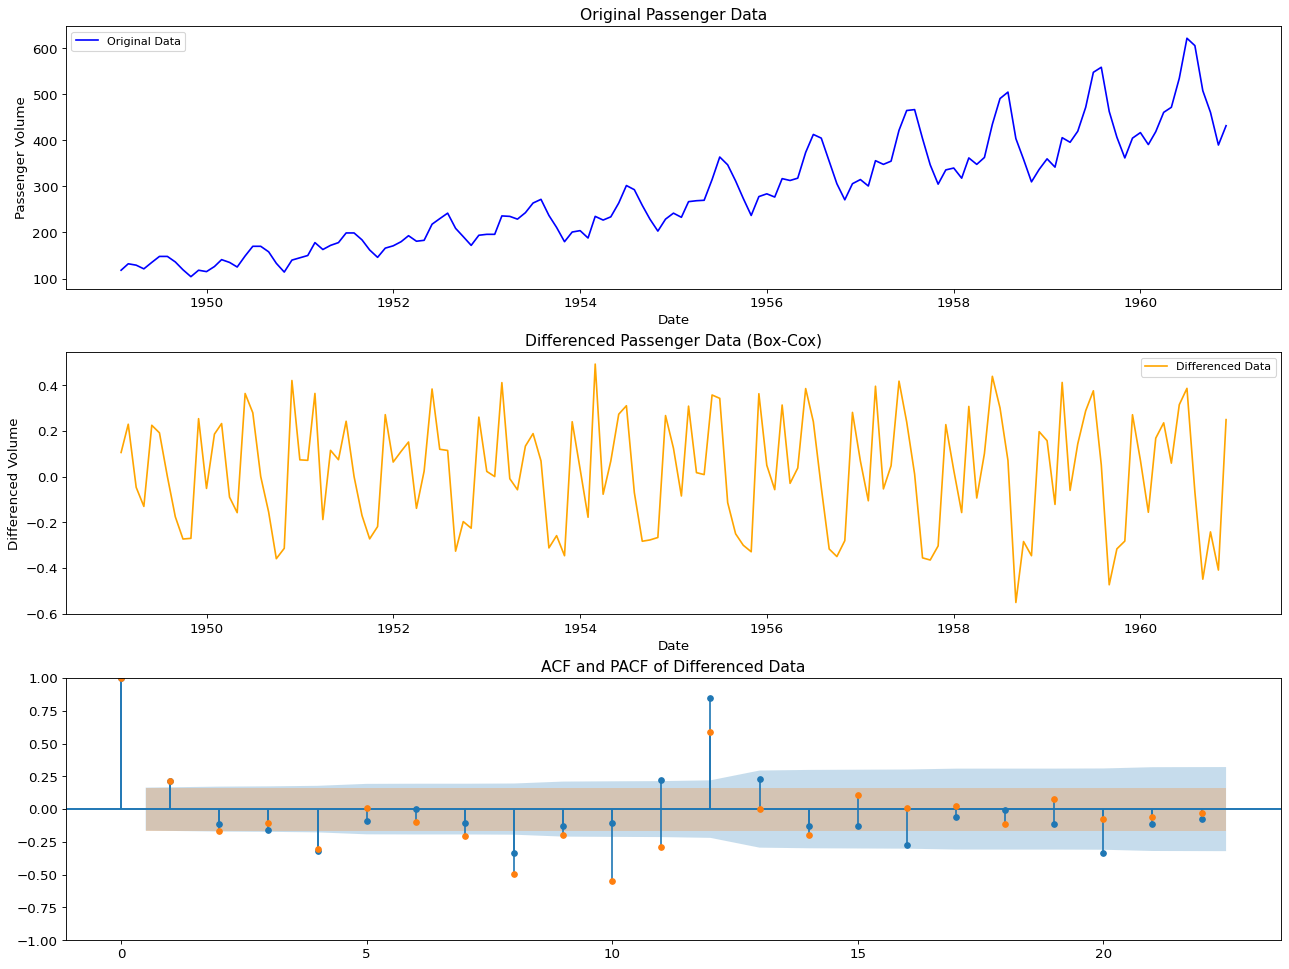

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from scipy.stats import boxcox

# Apply Box-Cox transformation
data['Passengers_Boxcox'], lam = boxcox(data['#Passengers'])

# Difference the data
data['Passenger_diff'] = data['Passengers_Boxcox'].diff()
data.dropna(inplace=True)

# Create a figure with three rows
fig, axes = plt.subplots(3, 1, figsize=(16, 12), dpi=80, constrained_layout=True)

# Plot the original series
axes[0].plot(data['Month'], data['#Passengers'], label="Original Data", color='blue')
axes[0].set_title("Original Passenger Data", fontsize=14)
axes[0].set_xlabel("Date", fontsize=12)
axes[0].set_ylabel("Passenger Volume", fontsize=12)
axes[0].legend()
axes[0].tick_params(axis='both', labelsize=12)

# Plot the differenced series
axes[1].plot(data['Month'], data['Passenger_diff'], label="Differenced Data", color='orange')
axes[1].set_title("Differenced Passenger Data (Box-Cox)", fontsize=14)
axes[1].set_xlabel("Date", fontsize=12)
axes[1].set_ylabel("Differenced Volume", fontsize=12)
axes[1].legend()
axes[1].tick_params(axis='both', labelsize=12)

# Plot ACF and PACF
plot_acf(data['Passenger_diff'], ax=axes[2])
plot_pacf(data['Passenger_diff'], ax=axes[2], method='ywm')
axes[2].set_title("ACF and PACF of Differenced Data", fontsize=14)
axes[2].tick_params(axis='both', labelsize=12)

# Show the plots
plt.show()


In [ ]:


# Split train and test
train = data.iloc[:-int(len(data) * 0.2)]
test = data.iloc[-int(len(data) * 0.2):]

# Build ARIMA model
model = ARIMA(train['Passengers_Boxcox'], order=(12, 1, 12)).fit()

# Forecast and apply inverse Box-Cox transformation
boxcox_forecasts = model.forecast(len(test))
forecasts = inv_boxcox(boxcox_forecasts, lam)



/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning:

An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/statespace/sarimax.py:966: UserWarning:

Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.

/usr/local/lib/python3.10/dist-packages/statsmodels/tsa/

In [ ]:
# Import packages
import plotly.graph_objects as go
from typing import List

def plot_forecasts(forecasts: List[float], title: str) -> None:
    """Function to plot the forecasts."""
    fig = go.Figure()
    # Plot training data
    fig.add_trace(go.Scatter(x=train['Month'], y=train['#Passengers'], name='Train'))
    # Plot test data
    fig.add_trace(go.Scatter(x=test['Month'], y=test['#Passengers'], name='Test'))
    # Plot forecasts
    fig.add_trace(go.Scatter(x=test['Month'], y=forecasts, name='Forecast'))

    # Update layout for better visuals
    fig.update_layout(template="simple_white", font=dict(size=18),
                      title_text=title, width=800, title_x=0.5,
                      height=400, xaxis_title='Date',
                      yaxis_title='Passenger Volume')
    fig.show()

# Plot the forecasts
plot_forecasts(forecasts=forecasts, title='ARIMA Forecast')


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate metrics
mae = mean_absolute_error(test["#Passengers"], forecasts)
rmse = np.sqrt(mean_squared_error(test["#Passengers"], forecasts))
mape = np.mean(np.abs((test["#Passengers"] - forecasts) / test["#Passengers"])) * 100

# Precision percentage
precision = 100 - mape

# Print results
print(f"MAE: {mae}")
print(f"RMSE: {rmse}")
print(f"MAPE: {mape:.2f}%")
print(f"Precision: {precision:.2f}%")


MAE: 19.744341442708723
RMSE: 23.468957246540107
MAPE: 9.38%
Precision: 90.62%
